# **Libraries**

In [1]:
from tensorflow import keras
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import os
import seaborn as sns
from sklearn import preprocessing
from sklearn.metrics import confusion_matrix, recall_score, precision_score,f1_score,accuracy_score
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from google.colab import drive
import time

In [2]:
# Set the seed for reproducibility to ensure consistent results across runs
np.random.seed(1958)
PYTHONHASHSEED = 0

# **Data Loading**

In [3]:
# 1. Mount Google Drive
drive.mount('/content/drive')
drive_path = '/content/drive/MyDrive/CMAPSSData/'

# 3. Load the datasets from Drive
try:
    train_df = pd.read_csv(os.path.join(drive_path, 'train_FD001.txt'), sep=" ", header=None)
    test_df = pd.read_csv(os.path.join(drive_path, 'test_FD001.txt'), sep=" ", header=None)

    print("Successfully loaded data from Google Drive!")
    print("\nTraining Data:")
    display(train_df.head(20))
    display(test_df.head(20))

except Exception as e:
    print("Error loading files:", e)

Mounted at /content/drive
Successfully loaded data from Google Drive!

Training Data:


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,NaN,NaN
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,NaN,NaN
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,NaN,NaN
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,NaN,NaN
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,NaN,NaN
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669,NaN,NaN
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,...,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774,NaN,NaN
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,...,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106,NaN,NaN
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,...,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066,NaN,NaN
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,...,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694,NaN,NaN


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,NaN,NaN
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,NaN,NaN
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,NaN,NaN
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,NaN,NaN
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,NaN,NaN
5,1,6,0.0012,0.0003,100.0,518.67,642.11,1579.12,1395.13,14.62,...,8127.46,8.4238,0.03,392,2388,100.0,38.91,23.3467,NaN,NaN
6,1,7,-0.0000,0.0002,100.0,518.67,642.11,1583.34,1404.84,14.62,...,8134.97,8.3914,0.03,391,2388,100.0,38.85,23.3952,NaN,NaN
7,1,8,0.0006,-0.0000,100.0,518.67,642.54,1580.89,1400.89,14.62,...,8125.93,8.4213,0.03,393,2388,100.0,39.05,23.3224,NaN,NaN
8,1,9,-0.0036,0.0000,100.0,518.67,641.88,1593.29,1412.28,14.62,...,8134.15,8.4353,0.03,391,2388,100.0,39.10,23.4521,NaN,NaN
9,1,10,-0.0025,-0.0001,100.0,518.67,642.07,1585.25,1398.64,14.62,...,8134.08,8.4093,0.03,391,2388,100.0,38.87,23.3820,NaN,NaN


In [4]:
# Drop columns with missing values in the training and test datasets
train_df.dropna(axis=1, inplace=True)
test_df.dropna(axis=1, inplace=True)

# Print the length of train and test datasets
print(len(train_df))
print(len(test_df))


20631
13096


In [5]:
# Define column names for the datasets
cols_names = ['id', 'cycle', 'setting1', 'setting2', 'setting3', 's1', 's2', 's3',
                     's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14',
                     's15', 's16', 's17', 's18', 's19', 's20', 's21']

# Assign the column names to the datasets
train_df.columns = cols_names
test_df.columns = cols_names

# Display first few rows to confirm correct column assignment
train_df.head(10)

,id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,...,522.32,2388.03,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,...,522.47,2388.03,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,...,521.79,2388.05,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,...,521.79,2388.06,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694


In [6]:
# Load the RUL data (additional RUL) for test dataset
truth_df = pd.read_csv(os.path.join(drive_path, 'RUL_FD001.txt'), sep=" ", header=None)
truth_df.head()

,0,1
0,112,NaN
1,98,NaN
2,69,NaN
3,82,NaN
4,91,NaN


In [7]:
# Drop columns with missing values in the ground truth dataset
truth_df.dropna(axis=1, inplace=True)
truth_df.head()

,0
0,112
1,98
2,69
3,82
4,91


# **Preprocessing**

**Generating Classification Target Variable**

To classify the cycles close to failure, we assign a value of 1 to the target variable failure_within_w1 for the corresponding engine id whenever the engine is close to failure.

In this case, w1 represents the window size, which is set to 30 cycles. This window defines how far ahead of the actual failure we want to detect the potential for maintenance.

Important Note: For the last cycle, when the engine is in a failed state, we want to predict if maintenance is required in the next x cycles (in this case, 30). The window size determines how early we can flag the maintenance. You can adjust the window size to 15, 30, 45, etc., depending on how proactively you want to predict potential failures and the acceptable level of prediction accuracy.

In this example, we are using a window size of 30 cycles. This means the task is to determine if maintenance is needed before the next 30 cycles of operation, and this information is crucial to avoid sudden breakdowns.

In [8]:
# Sort both train and test datasets by id and cycle to maintain order

train_df.sort_values(['id','cycle'], inplace=True)
test_df.sort_values(['id','cycle'], inplace=True)


In [9]:

# Extract the maximum number of cycles for each engine id.
rul = pd.DataFrame(train_df.groupby('id')['cycle'].max()).reset_index()

# Name the columns and merge them with the training data.
rul.columns = ['id', 'max']
train_df = train_df.merge(rul, on=['id'], how='left')

# Now subtract the current cycle from the max (maximum number of cycles) to calculate the remaining useful life.
train_df['RUL'] = train_df['max'] - train_df['cycle']

#The RUL is calculated for each id.
train_df[['id','cycle','max','RUL']].head()


,id,cycle,max,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187


We first determine the maximum cycle number for each engine by using groupby() and then merge these maximum values with the corresponding engine data.

Next, we calculate the Remaining Useful Life (RUL) by subtracting the current cycle value from the maximum cycle value. For instance, if an engine has a total life of 192 cycles and has already completed 50 cycles, its RUL would be 192 - 50 = 142.


In [10]:
# Drop the 'max' column as it is no longer needed
train_df.drop('max', axis=1, inplace=True)

Generate label column for training data

In [11]:
# Generate a label column for the training data based on whether an engine will fail within 'w1' cycles
w1 = 30
train_df['failure_within_w1'] = np.where(train_df['RUL'] <= w1, 1, 0)

In [12]:
# Make a separate feature for the normalized value of the cycle column.
train_df['cycle_norm'] = train_df['cycle']

# Using the difference function, we exclude these columns from the normalization process.
cols_normalize = train_df.columns.difference(['id','cycle','RUL','failure_within_w1'])

# MinMax normalization (from 0 to 1) of sensor data
min_max_scaler = preprocessing.MinMaxScaler()
norm_train_df = pd.DataFrame(min_max_scaler.fit_transform(train_df[cols_normalize]),
                             columns=cols_normalize,
                             index=train_df.index)

#Join the normalized and non-normalized data.
join_df = train_df[['id','cycle','RUL','failure_within_w1']].join(norm_train_df)
train_df = join_df.reindex(columns = train_df.columns)

train_df.head()

,id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s15,s16,s17,s18,s19,s20,s21,RUL,failure_within_w1,cycle_norm
0,1,1,0.459770,0.166667,0.0,0.0,0.183735,0.406802,0.309757,0.0,...,0.363986,0.0,0.333333,0.0,0.0,0.713178,0.724662,191,0,0.00000
1,1,2,0.609195,0.250000,0.0,0.0,0.283133,0.453019,0.352633,0.0,...,0.411312,0.0,0.333333,0.0,0.0,0.666667,0.731014,190,0,0.00277
2,1,3,0.252874,0.750000,0.0,0.0,0.343373,0.369523,0.370527,0.0,...,0.357445,0.0,0.166667,0.0,0.0,0.627907,0.621375,189,0,0.00554
3,1,4,0.540230,0.500000,0.0,0.0,0.343373,0.256159,0.331195,0.0,...,0.166603,0.0,0.333333,0.0,0.0,0.573643,0.662386,188,0,0.00831
4,1,5,0.390805,0.333333,0.0,0.0,0.349398,0.257467,0.404625,0.0,...,0.402078,0.0,0.416667,0.0,0.0,0.589147,0.704502,187,0,0.01108


Normalize the test data in the same manner

In [13]:
# We will perform MinMax normalization (from 0 to 1)
test_df['cycle_norm'] = test_df['cycle']

# MinMax normalization (from 0 to 1) of the sensor data only
norm_test_df = pd.DataFrame(min_max_scaler.transform(test_df[cols_normalize]),
                            columns=cols_normalize,
                            index=test_df.index)

#Join the normalized and non-normalized data (it does not have 'RUL' and 'failure_within_w1')
test_join_df = test_df[test_df.columns.difference(cols_normalize)].join(norm_test_df)
test_df = test_join_df.reindex(columns = test_df.columns)
test_df = test_df.reset_index(drop=True)

Label the test set like we dengine_id for the training data.

In [14]:
# Let's calculate the total RUL by summing up the maximum cycles given in the test set and the
# ground truth additional RUL.
rul = pd.DataFrame(test_df.groupby('id')['cycle'].max()).reset_index()
rul.columns = ['id', 'max']
truth_df.columns = ['additional_rul']

# The respective id can be obtained by adding 1 to the index, as the index starts from 0.
truth_df['id'] = truth_df.index + 1

# Add the max cycles given in the test set and the additional RUL given in the ground truth DataFrame.
truth_df['max'] = rul['max'] + truth_df['additional_rul']
truth_df.drop('additional_rul', axis=1, inplace=True)

# Generate the RUL for the test data.
test_df = test_df.merge(truth_df, on=['id'], how='left')
test_df['RUL'] = test_df['max'] - test_df['cycle']
test_df.drop('max', axis=1, inplace=True)

# Generate the label columns w0 and w1 for the test data.
test_df['failure_within_w1'] = np.where(test_df['RUL'] <= w1, 1, 0 )
test_df.head()


,id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s15,s16,s17,s18,s19,s20,s21,cycle_norm,RUL,failure_within_w1
0,1,1,0.632184,0.750000,0.0,0.0,0.545181,0.310661,0.269413,0.0,...,0.308965,0.0,0.333333,0.0,0.0,0.558140,0.661834,0.00000,142,0
1,1,2,0.344828,0.250000,0.0,0.0,0.150602,0.379551,0.222316,0.0,...,0.213159,0.0,0.416667,0.0,0.0,0.682171,0.686827,0.00277,141,0
2,1,3,0.517241,0.583333,0.0,0.0,0.376506,0.346632,0.322248,0.0,...,0.458638,0.0,0.416667,0.0,0.0,0.728682,0.721348,0.00554,140,0
3,1,4,0.741379,0.500000,0.0,0.0,0.370482,0.285154,0.408001,0.0,...,0.257022,0.0,0.250000,0.0,0.0,0.666667,0.662110,0.00831,139,0
4,1,5,0.580460,0.500000,0.0,0.0,0.391566,0.352082,0.332039,0.0,...,0.300885,0.0,0.166667,0.0,0.0,0.658915,0.716377,0.01108,138,0


# **Exploratory Data Analysis**

In [15]:
# Extract sensor columns (from cols_names starting from index 5)
sensor_cols = cols_names[5:]

# Create an interactive figure for all sensors of engine id=1
fig_all_sensors = go.Figure()

# Add each sensor's data as a separate trace in the plot
for sensor in sensor_cols:
    fig_all_sensors.add_trace(go.Scatter(
        x=train_df[train_df.id == 1].cycle,
        y=train_df[train_df.id == 1][sensor],
        mode='lines+markers',
        name=sensor
    ))

# Update layout for the plot
fig_all_sensors.update_layout(
    title="Sensor Data for Engine ID 1",
    xaxis_title="Cycle",
    yaxis_title="Sensor Values",
    template="plotly_white",
    font=dict(size=12),
    legend_title="Sensors",
    autosize=True
)

# Show the interactive plot
fig_all_sensors.show()

In [16]:
# Create an interactive figure for Engine ID 1, Sensor 1
fig_sensor1_engine1 = go.Figure()
fig_sensor1_engine1.add_trace(go.Scatter(
    x=train_df[train_df.id == 1].cycle,
    y=train_df[train_df.id == 1][sensor_cols[1]],
    mode='lines+markers',
    name="Sensor 1"
))
fig_sensor1_engine1.update_layout(
    title="Sensor 1 Data for Engine ID 1",
    xaxis_title="Cycle",
    yaxis_title="Sensor 1 Value",
    template="plotly_white",
    font=dict(size=12),
    legend_title="Sensors",
    autosize=True
)
fig_sensor1_engine1.show()


The values of Sensor 1 rise as the cycle number increases.
The values of Sensor 6 decrease as the cycle number increases.

The majority of other sensors show either an increasing or decreasing trend.

In [17]:
# Create an interactive figure for Engine ID 5, Sensor 1
fig_sensor1_engine5 = go.Figure()
fig_sensor1_engine5.add_trace(go.Scatter(
    x=train_df[train_df.id == 5].cycle,
    y=train_df[train_df.id == 5][sensor_cols[1]],
    mode='lines+markers',
    name="Sensor 1"
))
fig_sensor1_engine5.update_layout(
    title="Sensor 1 Data for Engine ID 5",
    xaxis_title="Cycle",
    yaxis_title="Sensor 1 Value",
    template="plotly_white",
    font=dict(size=12),
    legend_title="Sensors",
    autosize=True
)
fig_sensor1_engine5.show()


In [18]:
# Create an interactive figure for Engine ID 1, Sensor 6
fig_sensor6_engine1 = go.Figure()
fig_sensor6_engine1.add_trace(go.Scatter(
    x=train_df[train_df.id == 1].cycle,
    y=train_df[train_df.id == 1][sensor_cols[6]],
    mode='lines+markers',
    name="Sensor 6"
))
fig_sensor6_engine1.update_layout(
    title="Sensor 6 Data for Engine ID 1",
    xaxis_title="Cycle",
    yaxis_title="Sensor 6 Value",
    template="plotly_white",
    font=dict(size=12),
    legend_title="Sensors",
    autosize=True
)
fig_sensor6_engine1.show()


We have visualized Sensor 1 data for Engine ID 1 and Engine ID 5.
Both observations exhibit an upward trend as the cycle count increases.

In [19]:
# Create an interactive figure for Engine ID 50, Sensor 6
fig_sensor6_engine50 = go.Figure()
fig_sensor6_engine50.add_trace(go.Scatter(
    x=train_df[train_df.id == 50].cycle,
    y=train_df[train_df.id == 50][sensor_cols[6]],
    mode='lines+markers',
    name="Sensor 6"
))
fig_sensor6_engine50.update_layout(
    title="Sensor 6 Data for Engine ID 50",
    xaxis_title="Cycle",
    yaxis_title="Sensor 6 Value",
    template="plotly_white",
    font=dict(size=12),
    legend_title="Sensors",
    autosize=True
)
fig_sensor6_engine50.show()

We have visualized Sensor 6 data for Engine ID 1 and Engine ID 50.
Both observatios show a downward trend as the cycle count increases.
This suggests that as the sensor values approach a certain threshold, the aircraft may be nearing a failure.

# **Input Sequence**




In [20]:
# The sequence length to be used for predictions is as follows:
sequence_length = 50

In [21]:
# Function to generate sequences (samples, time steps, features) for a particular engine id.
def sequence_generator(feature_df, seq_length, seq_cols):
    """
    Generates sequences of specified length for a given engine id.

    Args:
        feature_df (DataFrame): The DataFrame containing the features for each engine id.
        seq_length (int): The length of the sequence to generate (number of timesteps).
        seq_cols (list): List of columns to include in the sequence.

    Yields:
        numpy.ndarray: A sequence of data with the shape (seq_length, num_features).
    """

    # Convert the selected columns of the DataFrame into a NumPy 2D array
    feature_array = feature_df[seq_cols].values
    num_elements = feature_array.shape[0]  # Number of rows in the feature array

    # Loop through the indices, creating sequences of length seq_length
    for start, stop in zip(range(0, num_elements - seq_length), range(seq_length, num_elements)):
        # Yield a sequence from start to stop
        yield feature_array[start:stop, :]

In [22]:
# Generate sequences for each engine ID with a specific feature (e.g., "s2")
seq_gen = (list(sequence_generator(train_df[train_df['id'] == id], sequence_length, ["s2"]))
           for id in train_df['id'].unique())

# Concatenate the sequences from all engine ids into one array and convert to a NumPy array
seq_set = np.concatenate(list(seq_gen)).astype(np.float32)

# Print the shape of the resulting sequence set
print(seq_set.shape)  # Output: (number of samples, number of time steps, number of features)

(15631, 50, 1)


In [23]:
def label_generator(label_df, seq_length, label):
    """
    Generates labels for the sequences based on the ground truth column 'label'.

    Args:
        label_df (DataFrame): The DataFrame containing the labels.
        seq_length (int): The length of the sequence.
        label (str): The column name representing the label.

    Returns:
        numpy.ndarray: A 2D array of labels.
    """
    label_array = label_df[label].values
    num_elements = label_array.shape[0]
    return label_array[seq_length:num_elements, :]

In [24]:
# Generate labels [[142,1], [121, 1], [3]] --> [1, 2, 3] (ntotal, 1).
label_gen = [label_generator(train_df[train_df['id']==id], sequence_length, ['failure_within_w1'])
             for id in train_df['id'].unique()]
label_set = np.concatenate(label_gen).astype(np.float32)
label_set.shape

(15631, 1)

In [25]:
# Pick the feature columns.
sensor_cols = ['s' + str(i) for i in range(1,22)]
sequence_cols_25 = ['setting1', 'setting2', 'setting3', 'cycle_norm']
sequence_cols_25.extend(sensor_cols) # Add the elements of sensor_cols into sequence_cols.

In [26]:
# Generate sequences for each engine id.
# unique() returns all the unique ids in a list.

seq_gen = (list(sequence_generator(train_df[train_df['id']==id], sequence_length, sequence_cols_25)) #We will take all the features (25).
           for id in train_df['id'].unique())

# Concatenate the sequences of the different engine ids into one and convert it into a NumPy array [(142, 50, 25), ...] --> [(ntotal, 50, 25)].
seq_set_f25 = np.concatenate(list(seq_gen)).astype(np.float32)

#The shape denotes (number of samples, number of time steps, number of features).
seq_set_f25.shape

(15631, 50, 25)

# **Model**

In [27]:
# Model 1 Architecture:
# Layer 1: LSTM (80 units with 0.2 dropout)
# Layer 2: LSTM (40 units with 0.2 dropout)
# Layer 3: Dense layer (sigmoid activation)

features_dim = seq_set_f25.shape[2]  # Number of features
out_dim = label_set.shape[1]         # 1 Label (Target variable: failure_within_w1)

print("Features dimension:", features_dim)
print("Output dimension:", out_dim)

# Initialize the Sequential model
model = Sequential()

# Layer 1: LSTM with 80 units and return_sequences=True
model.add(LSTM(
    units=80,
    input_shape=(sequence_length, features_dim),
    return_sequences=True
))
model.add(Dropout(0.2))  # Dropout for regularization

# Layer 2: LSTM with 40 units and return_sequences=False
model.add(LSTM(
    units=40,
    return_sequences=False
))
model.add(Dropout(0.2))  # Dropout for regularization

# Layer 3: Dense output layer with sigmoid activation
model.add(Dense(
    units=out_dim,
    activation='sigmoid'
))

# Compile the model with binary_crossentropy loss and Adam optimizer
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Display the model summary
print(model.summary())

Features dimension: 25
Output dimension: 1


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 80)         │        33,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 80)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 40)             │        19,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,321 (208.29 KB)

 Trainable params: 53,321 (208.29 KB)

 Non-trainable params: 0 (0.00 B)

None


In [28]:
# Define path to save model
model_path = '/content/binary_model.keras'

# Training configuration
epochs = 200  # Maximum number of training epochs
batch_size = 200  # Number of samples per training batch

# Measure training start time
start = time.time()

# Train the model
history = model.fit(
    seq_set_f25,
    label_set,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.05,
    verbose=2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            min_delta=0,
            patience=10,
            verbose=0,
            mode='min'
        ),
        keras.callbacks.ModelCheckpoint(
            model_path,
            monitor='val_loss',
            save_best_only=True,
            mode='min',
            verbose=0
        )
    ]
)

# Measure training end time
end = time.time()

# Output total training time
print("Total time taken for training:", "{:.2f}".format((end - start)), "secs")


Epoch 1/200
75/75 - 6s - 81ms/step - accuracy: 0.8903 - loss: 0.2736 - val_accuracy: 0.9629 - val_loss: 0.0924
Epoch 2/200
75/75 - 1s - 9ms/step - accuracy: 0.9608 - loss: 0.0992 - val_accuracy: 0.9540 - val_loss: 0.1166
Epoch 3/200
75/75 - 1s - 10ms/step - accuracy: 0.9641 - loss: 0.0867 - val_accuracy: 0.9757 - val_loss: 0.0603
Epoch 4/200
75/75 - 1s - 9ms/step - accuracy: 0.9701 - loss: 0.0725 - val_accuracy: 0.9668 - val_loss: 0.0626
Epoch 5/200
75/75 - 1s - 9ms/step - accuracy: 0.9720 - loss: 0.0662 - val_accuracy: 0.9859 - val_loss: 0.0356
Epoch 6/200
75/75 - 1s - 9ms/step - accuracy: 0.9714 - loss: 0.0686 - val_accuracy: 0.9872 - val_loss: 0.0378
Epoch 7/200
75/75 - 1s - 9ms/step - accuracy: 0.9761 - loss: 0.0578 - val_accuracy: 0.9744 - val_loss: 0.0496
Epoch 8/200
75/75 - 1s - 9ms/step - accuracy: 0.9702 - loss: 0.0695 - val_accuracy: 0.9821 - val_loss: 0.0389
Epoch 9/200
75/75 - 1s - 9ms/step - accuracy: 0.9741 - loss: 0.0622 - val_accuracy: 0.9770 - val_loss: 0.0461
Epoch 10

# **Training set Evaluation**


In [29]:
# Plotting the change in model accuracy on train and validation sets
fig = go.Figure()

# Add train accuracy
fig.add_trace(go.Scatter(
    x=list(range(1, len(history.history['accuracy']) + 1)),
    y=history.history['accuracy'],
    mode='lines',
    name='Train Accuracy',
    line=dict(color='blue', width=2)
))

# Add validation accuracy
fig.add_trace(go.Scatter(
    x=list(range(1, len(history.history['val_accuracy']) + 1)),
    y=history.history['val_accuracy'],
    mode='lines',
    name='Validation Accuracy',
    line=dict(color='red', width=2)
))

# Update layout for accuracy plot
fig.update_layout(
    title='Model Accuracy',
    xaxis_title='Epochs',
    yaxis_title='Accuracy',
    template='plotly_white',
    legend_title='Accuracy Type',
    font=dict(size=15),
    width=1000,
    height=400
)

# Show the figure
fig.show()

# Plotting model loss for train and validation sets
fig_loss = go.Figure()

# Add train loss
fig_loss.add_trace(go.Scatter(
    x=list(range(1, len(history.history['loss']) + 1)),
    y=history.history['loss'],
    mode='lines',
    name='Train Loss',
    line=dict(color='blue', width=2)
))

# Add validation loss
fig_loss.add_trace(go.Scatter(
    x=list(range(1, len(history.history['val_loss']) + 1)),
    y=history.history['val_loss'],
    mode='lines',
    name='Validation Loss',
    line=dict(color='red', width=2)
))

# Update layout for loss plot
fig_loss.update_layout(
    title='Model Loss',
    xaxis_title='Epochs',
    yaxis_title='Loss',
    template='plotly_white',
    legend_title='Loss Type',
    font=dict(size=15),
    width=1000,
    height=400
)

# Show the figure
fig_loss.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9630 - loss: 0.0814
Train Accuracy: 0.9651973843574524
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
Train Precision:  0.8526490066225165
Train Recall:  0.9967741935483871
Train F1-Score:  0.9190957763236169


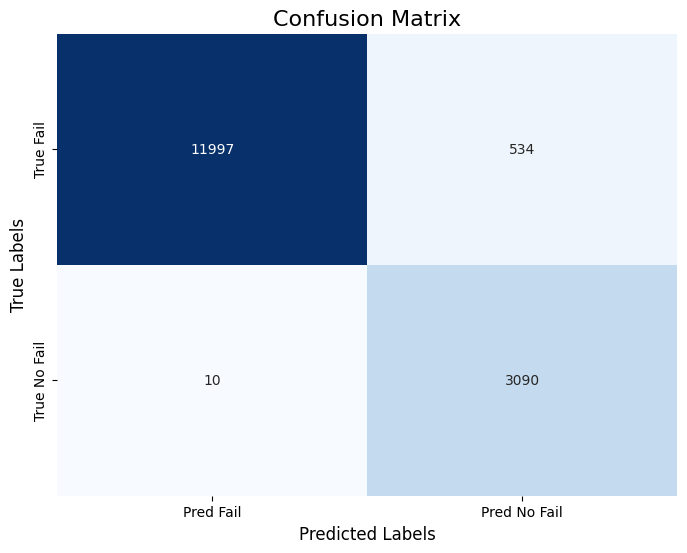

In [30]:
# Evaluate the model's performance
scores = model.evaluate(seq_set_f25, label_set, verbose=1, batch_size=50)
print('Train Accuracy: {}'.format(scores[1]))

# Generate predictions and compute confusion matrix
y_pred = (model.predict(seq_set_f25, verbose=1, batch_size=200) > 0.5).astype("int32")
y_true = label_set

# Save predictions to a CSV file
test_set = pd.DataFrame(y_pred)
test_set.to_csv('binary_submit_train.csv', index=None)

# Calculate Precision, Recall, F1-Score, and Accuracy
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print Precision, Recall and F1-Score
print("Train Precision: ", precision)
print("Train Recall: ", recall)
print("Train F1-Score: ", f1)



# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred Fail", "Pred No Fail"],
            yticklabels=["True Fail", "True No Fail"])

# Titles and labels
plt.title("Confusion Matrix", fontsize=16)
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.show()


# **Test set Evaluation**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
Test Precision:  0.9230769230769231
Test Recall:  0.96
Test F1-Score:  0.9411764705882353
Test Accuracy:  0.967741935483871
Test Confusion Matrix:
[[66  2]
 [ 1 24]]


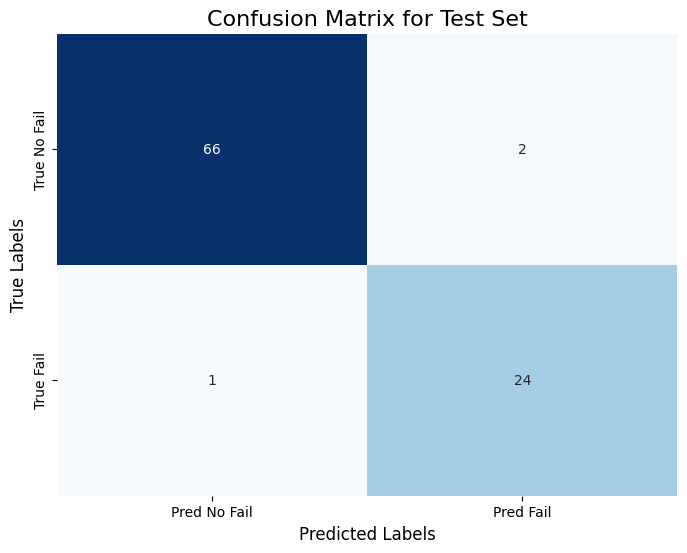

In [31]:
# Considering all the last sequences of test set
last_test_seq = [test_df[test_df['id']==id][sequence_cols_25].values[-sequence_length:]
                       for id in test_df['id'].unique() if len(test_df[test_df['id']==id]) >= sequence_length]
last_test_seq = np.asarray(last_test_seq).astype(np.float32)

# Get labels of test set
y_mask = [len(test_df[test_df['id']==id]) >= sequence_length for id in test_df['id'].unique()]
last_test_label = test_df.groupby('id')['failure_within_w1'].nth(-1)[y_mask].values
last_test_label = last_test_label.reshape(last_test_label.shape[0],1).astype(np.float32)

# If best model weights were saved then load it
if os.path.isfile(model_path):
    estimator = load_model(model_path)

# Make predictions for the test set
y_pred_test = (estimator.predict(last_test_seq, verbose=1, batch_size=200) > 0.5).astype("int32")
y_true_test = last_test_label  # Actual labels for test set

# Save predictions to a CSV file
test_set = pd.DataFrame(y_pred_test)
test_set.to_csv('binary_submit_test.csv', index=None)

# Evaluate the model's performance on the test data
precision_test = precision_score(y_true_test, y_pred_test)
recall_test = recall_score(y_true_test, y_pred_test)
f1_test = f1_score(y_true_test, y_pred_test)
accuracy_test = accuracy_score(y_true_test, y_pred_test)

# Print Precision, Recall, F1-Score, and Accuracy for the test set
print("Test Precision: ", precision_test)
print("Test Recall: ", recall_test)
print("Test F1-Score: ", f1_test)
print("Test Accuracy: ", accuracy_test)

# Generate confusion matrix for the test set
cm_test = confusion_matrix(y_true_test, y_pred_test)
print("Test Confusion Matrix:")
print(cm_test)

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred No Fail", "Pred Fail"],
            yticklabels=["True No Fail", "True Fail"])

# Titles and labels
plt.title("Confusion Matrix for Test Set", fontsize=16)
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.show()

In [32]:
# Additional evaluation metrics (Precision, Recall, F1-score, Accuracy)
metrics_df = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "Accuracy"],
    "Score": [precision_test, recall_test, f1_test, accuracy_test]
})

# Display the evaluation metrics table
print(metrics_df)

      Metric     Score
0  Precision  0.923077
1     Recall  0.960000
2   F1-Score  0.941176
3   Accuracy  0.967742


In [33]:
# Plotting Predicted vs Actual values
fig_pred_actual = go.Figure()

# Add predicted values
fig_pred_actual.add_trace(go.Scatter(
    x=list(range(len(y_pred_test))),
    y=y_pred_test.flatten(),
    mode='lines+markers',
    name='Predicted',
    line=dict(color='blue', width=2)
))

# Add actual values
fig_pred_actual.add_trace(go.Scatter(
    x=list(range(len(y_true_test))),
    y=y_true_test.flatten(),
    mode='lines+markers',
    name='Actual',
    line=dict(color='green', width=2)
))

# Update layout for Predicted vs Actual plot
fig_pred_actual.update_layout(
    title='Predicted vs Actual Values',
    xaxis_title='Sample Index',
    yaxis_title='Value',
    template='plotly_white',
    legend_title='Type',
    font=dict(size=15),
    width=1000,
    height=400
)

# Show the interactive figure
fig_pred_actual.show()